# A burden and spacing surface: two levers at once on three predictors

**Question:** What shape does each predictor's burden and spacing surface have?

**Level 2: The method in practice** · Needs: 06-design-response/01-moving-one-lever-at-a-time · Reading time: about 35 minutes

## Objectives

Moving one lever at a time hides how two of them interact. The Design group of the web application draws a response surface over the burden and the spacing, with every model recomputed on the design the reader changes. This notebook builds that surface for one Akdaglar blast with the engine, then asks whether its shape belongs to the predictor or to the blast.

By the end you will have:

- built a 7 by 7 grid of designs from one blast with two `apply_variant` calls per point, and reconstructed the rock volume of each design;
- predicted the grid with the classical equation, the published regression and gradient boosting, one predictor per cell, and drawn the three surfaces on one colour scale;
- fitted the log-log slope of each surface against the rock volume and the exponents on the burden and the spacing, and compared them with the classical values;
- repeated the sweep on all 22 blasts of the campaign and seen which slopes are a property of the predictor.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

The setup cell imports the packages and the product's variant tools (`apply_variant`, `is_degenerate`, the registry of cases and the `Variant` record), prints the versions, loads the 22 Akdaglar blasts and defines `Table`. `display` shows a table in the middle of a cell that also draws or prints.

In [1]:
# Imports, package versions and the corpus loader
from importlib.metadata import version
from pathlib import Path
import sys

sys.path.insert(0, str(Path("../../../data-pipeline")))
from pipeline.cases.fragmenta_cases import Variant
from pipeline.model.blasts import apply_variant, blasts_for_case, is_degenerate
from pipeline.registry import get_case
from IPython.display import display

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

train = bf.load_training_corpus()
print(len(train), "blasts from", len({b.site for b in train}), "campaigns")

class Table:
    """Rows under a header, shown as a Markdown table"""

    def __init__(self, header, rows):
        self.header = list(header)
        self.rows = [[str(cell) for cell in row] for row in rows]

    def _repr_markdown_(self):
        lines = ["| " + " | ".join(self.header) + " |", "|" + "---|" * len(self.header)]
        lines += ["| " + " | ".join(row) + " |" for row in self.rows]
        return "\n".join(lines)

    __repr__ = _repr_markdown_

case = get_case("real-akdaglar")
blasts = blasts_for_case(case)

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2
97 blasts from 10 campaigns


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The Akdaglar blasts and the rest of the corpus, to train gradient boosting | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The variant mechanism and the degenerate-design guard | this repository (MIT) | the product's own licence | `data-pipeline/pipeline/model/blasts.py`, imported by path |

The sweep factors, 0.7 to 1.3 in seven steps, are inputs of this notebook: a range around the base design that stays inside the envelope of the corpus.

## Method

A grid point is a blast with two multipliers applied: one on the burden-to-diameter ratio `B/D`, which scales every length of the pattern together because the diameter is fixed, and one on the spacing-to-burden ratio `S/B`, which stretches the spacing alone. `apply_variant` applies one multiplier, so two calls build one point, and `is_degenerate` checks that the result is still a blast. `reconstruct_pattern` then turns the ratios into metres and gives the rock volume per hole `V = B S H`.

With a multiplier `f_b` on the burden ratio and `f_s` on the spacing ratio, the volume changes by `f_b^3 f_s`: the burden multiplier scales the burden, the spacing and the height, and the spacing multiplier only the spacing. For the classical equation, `x50 = A (V/Q)^0.8 Q^(1/6) ...` (Kuznetsov 1973 as printed by Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013), at a fixed powder factor `V/Q` is constant and the size varies only as `Q^(1/6)`, that is as `V^(1/6)`. Its surface is therefore a function of the volume alone, with an exponent of 1/6 on the volume, 1/2 on `f_b` and 1/6 on `f_s`.

The regression is a power law of the seven ratios (Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957): smooth, with one fitted exponent per ratio and no reason to depend on the volume alone. Gradient boosting (Sui et al. 2025, https://doi.org/10.3390/app15031254) can only return the values its leaves hold.

### Step 1: the base blast, the predictors and the multipliers

The cell takes blast `Ad1` of Akdaglar as the base design, builds the three predictors (gradient boosting is trained without Akdaglar) and fixes seven multipliers from 0.7 to 1.3.

In [2]:
# One base blast, the three predictors and a 7 by 7 grid of multipliers
base = next(blast for blast in blasts if blast.blast_id == "Ad1")
arms = {
    "kuznetsov": bf.Kuznetsov(dict(bf.SITE_ROCK_FACTOR)),
    "published-regression": bf.PublishedRegression(),
    "xgboost": bf.default_arms()["xgboost"]().fit([blast for blast in train if blast.site != case.site]),
}
factors = np.linspace(0.7, 1.3, 7)
print("base design:", base.blast_id, "|", base.site, "| B/D", base.B_over_D, "| S/B", base.S_over_B, "| H/B",
    base.H_over_B)
print("multipliers:", [round(float(f), 2) for f in factors])

base design: Ad1 | Akdaglar | B/D 28.09 | S/B 1.2 | H/B 4.4
multipliers: [0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3]


### Step 2: the 49 designs and their rock volume

For every pair of multipliers the cell builds the design with two `apply_variant` calls and reconstructs its volume. It counts the degenerate designs, which would have to be left blank, and prints the range of volumes the grid covers.

In [3]:
# Build the 49 designs with two apply_variant calls each and reconstruct the rock volume of every one
designs = {}
volume = np.full((7, 7), np.nan)
for i, burden_factor in enumerate(factors):
    for j, spacing_factor in enumerate(factors):
        wider_burden = apply_variant(base, Variant("grid-b", "", "", "B_over_D", float(burden_factor)))
        designs[i, j] = apply_variant(wider_burden, Variant("grid-s", "", "", "S_over_B", float(spacing_factor)))
        volume[i, j] = bf.reconstruct_pattern(designs[i, j]).rock_volume_m3
degenerate = sum(is_degenerate(design) is not None for design in designs.values())
surface = {}
print("designs:", len(designs), "| degenerate:", degenerate)
print(f"rock volume per hole, base = {volume[3, 3]:.1f} m3")
print(f"range {volume.min():.1f} - {volume.max():.1f} m3")

designs: 49 | degenerate: 0
rock volume per hole, base = 82.5 m3
range 19.8 - 235.6 m3


**What the output shows.** No design of the grid is degenerate, and the volume per hole runs from 19.8 m3 to 235.6 m3 around the base value of 82.5 m3: a factor of twelve between the corners, because the volume moves with the cube of one multiplier. A sweep from 0.7 to 1.3 is therefore not a small perturbation of the pattern; it is the range between a tight and a very open grid. **What it does not show:** whether the blasts at the corners could be fired. The product only guarantees they are still blasts. The next three cells predict the whole grid, one predictor each.

### Step 3: predict the grid, one predictor per cell

**The classical equation** first. The cell predicts every design, skipping any degenerate one, and prints the range of sizes and how many distinct values the 49 points produce.

In [4]:
# Predict the grid with kuznetsov
grid = np.full((7, 7), np.nan)
for (i, j), design in designs.items():
    if is_degenerate(design) is None:
        grid[i, j] = arms["kuznetsov"].predict_one(design).x50_m
surface["kuznetsov"] = grid
distinct = len(np.unique(np.round(grid, 9)))
print("kuznetsov             ", f"min {np.nanmin(grid):.4f} m | max {np.nanmax(grid):.4f} m",
    f"| distinct values: {distinct}")

kuznetsov              min 0.1705 m | max 0.2576 m | distinct values: 49


**The published regression** next, with the same loop. It is a power law, so it should also return 49 distinct values, over a range of its own.

In [5]:
# Predict the grid with published-regression
grid = np.full((7, 7), np.nan)
for (i, j), design in designs.items():
    if is_degenerate(design) is None:
        grid[i, j] = arms["published-regression"].predict_one(design).x50_m
surface["published-regression"] = grid
distinct = len(np.unique(np.round(grid, 9)))
print("published-regression  ", f"min {np.nanmin(grid):.4f} m | max {np.nanmax(grid):.4f} m",
    f"| distinct values: {distinct}")

published-regression   min 0.1341 m | max 0.2450 m | distinct values: 49


**Gradient boosting** last. A tree ensemble returns only what its leaves hold, so the count of distinct values is the number to watch.

In [6]:
# Predict the grid with xgboost
grid = np.full((7, 7), np.nan)
for (i, j), design in designs.items():
    if is_degenerate(design) is None:
        grid[i, j] = arms["xgboost"].predict_one(design).x50_m
surface["xgboost"] = grid
distinct = len(np.unique(np.round(grid, 9)))
print("xgboost               ", f"min {np.nanmin(grid):.4f} m | max {np.nanmax(grid):.4f} m",
    f"| distinct values: {distinct}")

xgboost                min 0.2185 m | max 0.2870 m | distinct values: 17


### Step 4: the three surfaces

The figure draws the three grids side by side on one colour scale, so that differences of level and of shape are both readable. The white lines join the designs with the same rock volume. A predictor that depends on the volume alone has constant colour along them.

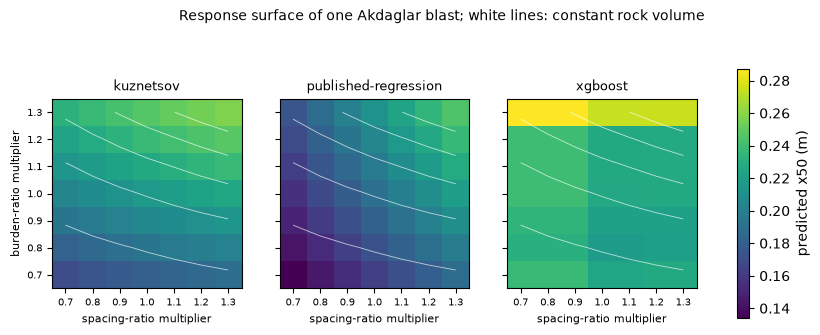

In [7]:
# The three surfaces on one colour scale; the centre cell is the base design
low = min(np.nanmin(grid) for grid in surface.values())
high = max(np.nanmax(grid) for grid in surface.values())
fig, axes = plt.subplots(1, 3, figsize=(10.4, 3.8), sharey=True)
for ax, (name, grid) in zip(axes, surface.items()):
    image = ax.imshow(grid, origin="lower", vmin=low, vmax=high, cmap="viridis")
    ax.contour(volume, levels=5, colors="white", linewidths=0.6, alpha=0.7)
    ax.set_xticks(range(7), [f"{f:.1f}" for f in factors], fontsize=7)
    ax.set_yticks(range(7), [f"{f:.1f}" for f in factors], fontsize=7)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("spacing-ratio multiplier", fontsize=8)
axes[0].set_ylabel("burden-ratio multiplier", fontsize=8)
fig.colorbar(image, ax=axes, shrink=0.85, label="predicted x50 (m)")
fig.suptitle("Response surface of one Akdaglar blast; white lines: constant rock volume", fontsize=10)
plt.show()

**What the figure shows.** The classical surface (left) has constant colour along the white lines: it is a function of the rock volume, and it grows with both multipliers, from 0.1705 m to 0.2576 m. The regression (middle) is smooth too, from 0.1341 m to 0.2450 m, but its colour crosses the white lines: it responds more to the spacing than to the burden, so designs of equal volume are not equal in size. The boosting surface (right) is a staircase of flat blocks over 17 distinct values, between 0.2185 m and 0.2870 m, with its coarsest block at the widest burden. **What it does not show:** which surface is right, since no field data records the response of a pit to the pattern; and it shows one blast. **What follows:** the next cells measure the shape instead of eyeballing it.

### Step 5: the shape as numbers

Two fits per surface over the 49 points. First `ln x50 = a + s ln V`, the log-log slope `s` against the rock volume and its r2: a pure power of the volume is a straight line with r2 equal to 1. Second `ln x50 = a + b ln f_b + c ln f_s`, the exponents on the two multipliers separately, which the classical equation fixes at 1/2 and 1/6. The table gives both, and the figure draws every design on the log-log plane with its fitted line.

In [8]:
# Fit ln x50 = a + b ln(burden multiplier) + c ln(spacing multiplier) on the grid and the slope against ln V
log_b = np.log(np.repeat(factors, 7))
log_s = np.log(np.tile(factors, 7))
log_v = np.log(volume.ravel())
slopes = {}
rows = []
for name, grid in surface.items():
    log_x = np.log(grid.ravel())
    slope, intercept = np.polyfit(log_v, log_x, 1)
    elasticity = np.linalg.lstsq(np.column_stack([np.ones(49), log_b, log_s]), log_x, rcond=None)[0]
    r2 = 1 - np.sum((log_x - (slope * log_v + intercept)) ** 2) / np.sum((log_x - log_x.mean()) ** 2)
    slopes[name] = (slope, intercept, r2)
    rows.append((name, f"{slope:.4f}", f"{r2:.3f}", f"{elasticity[1]:.3f}", f"{elasticity[2]:.3f}"))
display(Table(["predictor", "slope of ln x50 on ln V", "r2 of that line", "burden exponent", "spacing exponent"],
    rows))
print("the classical equation on paper:", f"1/6 = {1 / 6:.4f}", "| burden", f"{3 / 6:.3f}", "| spacing",
    f"{1 / 6:.3f}")

| predictor | slope of ln x50 on ln V | r2 of that line | burden exponent | spacing exponent |
|---|---|---|---|---|
| kuznetsov | 0.1667 | 1.000 | 0.500 | 0.167 |
| published-regression | 0.1828 | 0.694 | 0.427 | 0.547 |
| xgboost | 0.0545 | 0.225 | 0.217 | -0.105 |

the classical equation on paper: 1/6 = 0.1667 | burden 0.500 | spacing 0.167


The next cell puts the 49 designs of each predictor on the log-log plane against the rock volume, with the fitted line behind them. A pure power law is a straight line through every point, so what matters is how tightly each colour hugs its line.

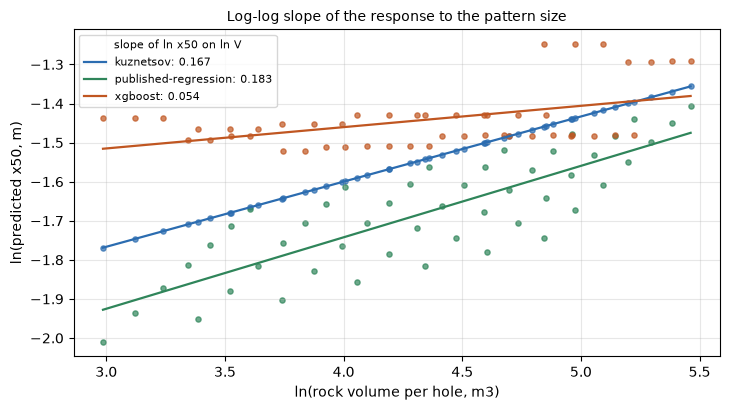

In [9]:
# ln x50 against ln rock volume for the 49 designs, with the fitted line of each predictor
fig, ax = plt.subplots(figsize=(7.4, 4.2))
colors = {"kuznetsov": "#2b6cb0", "published-regression": "#2f855a", "xgboost": "#c05621"}
log_v = np.log(volume.ravel())
for name, grid in surface.items():
    slope, intercept, r2 = slopes[name]
    ax.scatter(log_v, np.log(grid.ravel()), s=14, color=colors[name], alpha=0.7)
    ax.plot(np.sort(log_v), slope * np.sort(log_v) + intercept, color=colors[name], lw=1.6,
        label=f"{name}: {slope:.3f}")
ax.set_xlabel("ln(rock volume per hole, m3)")
ax.set_ylabel("ln(predicted x50, m)")
ax.set_title("Log-log slope of the response to the pattern size", fontsize=10)
ax.legend(fontsize=8, title="slope of ln x50 on ln V", title_fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**What the figure shows.** The classical points lie exactly on a line of slope 0.1667, which is 1/6, with r2 equal to 1.000, and its exponents are 0.500 on the burden and 0.167 on the spacing, as the equation says. The regression's points scatter around a steeper line (slope 0.1828) with r2 of only 0.694: it is not a function of the volume alone, and its exponents are 0.427 on the burden and 0.547 on the spacing, so it makes the spacing three times as influential as the classical equation does and the burden slightly less. The boosting points form a flat cloud (slope 0.0545, r2 0.225) with a negative exponent on the spacing, -0.105. **What it does not show:** that a line is the right model of a staircase; the fit only summarises its tilt. **What follows:** the regression and the classical equation disagree about how the pattern trades burden for spacing.

### Step 6: is the shape the predictor's or the blast's?

One blast could be unrepresentative. The cell repeats the whole sweep (the 49 designs, the volumes, the three predictions and the slope fit) on each of the 22 blasts of the campaign, and keeps the slope of each predictor for each blast.

In [10]:
# Repeat the sweep on all 22 Akdaglar blasts and keep the log-log slope of each predictor, each time
all_slopes = {name: [] for name in arms}
for blast in blasts:
    designs_of = {}
    for i, burden_factor in enumerate(factors):
        for j, spacing_factor in enumerate(factors):
            step = apply_variant(blast, Variant("grid-b", "", "", "B_over_D", float(burden_factor)))
            designs_of[i, j] = apply_variant(step, Variant("grid-s", "", "", "S_over_B", float(spacing_factor)))
    log_v = np.log([bf.reconstruct_pattern(d).rock_volume_m3 for d in designs_of.values()])
    for name, arm in arms.items():
        log_x = np.log([arm.predict_one(d).x50_m for d in designs_of.values()])
        all_slopes[name].append(np.polyfit(log_v, log_x, 1)[0])
rows = [(n, f"{min(v):+.3f}", f"{np.median(v):+.3f}", f"{max(v):+.3f}", sum(s > 0 for s in v)) for n,
    v in all_slopes.items()]
Table(["predictor", "smallest slope", "median", "largest slope", "blasts with positive slope (of 22)"], rows)

| predictor | smallest slope | median | largest slope | blasts with positive slope (of 22) |
|---|---|---|---|---|
| kuznetsov | +0.167 | +0.167 | +0.167 | 22 |
| published-regression | +0.183 | +0.183 | +0.183 | 22 |
| xgboost | -0.105 | -0.030 | +0.062 | 4 |

The next cell draws, for each predictor, the slope of the 22 blasts as 22 points on one column, with the classical 1/6 as a dashed line and zero as a thin grey line. A shape that belongs to the predictor gives a single point repeated; a shape that belongs to the blast gives a spread.

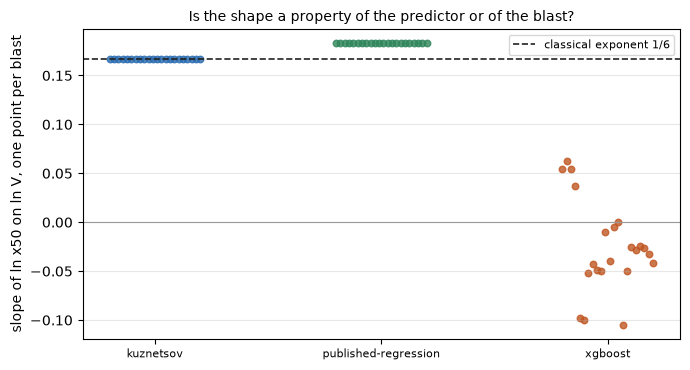

In [11]:
# The slope of each of the 22 blasts per predictor; the dashed line is the classical 1/6
fig, ax = plt.subplots(figsize=(7, 3.8))
for k, (name, values) in enumerate(all_slopes.items()):
    ax.scatter(np.full(len(values), k) + np.linspace(-0.2, 0.2, len(values)), values, s=22, color=colors[name],
        alpha=0.8)
ax.axhline(1 / 6, color="#222", ls="--", lw=1.2, label="classical exponent 1/6")
ax.axhline(0, color="#999", lw=0.8)
ax.set_xticks(range(len(all_slopes)), list(all_slopes), fontsize=8)
ax.set_ylabel("slope of ln x50 on ln V, one point per blast")
ax.set_title("Is the shape a property of the predictor or of the blast?", fontsize=10)
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

**What the figure shows.** For the classical equation the 22 slopes are one point at +0.167, and for the regression one point at +0.183: the same on every blast, which is what a fixed functional form means. The boosting slopes are scattered from -0.105 to +0.062 around a median of -0.030, and only 4 of the 22 are positive: for most blasts the learned surface falls as the pattern opens, against both closed forms. **What it does not show:** that the learned slope is wrong; the training rows may not support a trend at this scale. **What follows:** the shape of the classical and regression surfaces belongs to the predictor and is the same for every blast, whereas the shape of the learned surface belongs to the blast and to the position of its leaves, and carries no consistent sign.

## Results

**Answer:** the classical surface is a smooth power of the rock volume, the regression's is a smooth power of the two ratios with a different balance, and the learned surface is a staircase with no consistent direction. The classical slope of ln x50 on ln V is 0.1667, equal to 1/6, with r2 of 1.000 and exponents of 0.500 and 0.167 on the burden and the spacing. The regression's slope is 0.1828 with r2 0.694, because its exponents (0.427 on the burden, 0.547 on the spacing) do not combine into a function of the volume. Gradient boosting returns 17 distinct values on the 49 designs of the base blast, with a slope of 0.0545 and r2 of 0.225, and across the 22 blasts its slope runs from -0.105 to +0.062, positive in only 4.

The two closed forms are therefore reproducible properties of the predictor, the same on all 22 blasts (+0.167 and +0.183), while the learned shape is not: it cannot be summarised by one exponent, and the product shows the learned surface as a surface, not as a trend.

**What this does not show.** All three surfaces are model responses on blasts of one campaign, over a sweep that covers a factor of twelve in rock volume. No dataset records what changing the pattern does at a given pit, so none of the surfaces can be called the right one. The surface answers what each model says, not what the muckpile will look like.

## Summary

- Two `apply_variant` calls build a grid point, `is_degenerate` guards it and `reconstruct_pattern` gives its rock volume; 49 designs cover a factor of twelve in volume.
- The classical surface is a power 1/6 of the volume (r2 1.000); the regression is smooth but not a function of the volume (r2 0.694); boosting is a staircase of 17 values.
- The classical and regression slopes are the same on all 22 blasts; the boosting slope changes sign from blast to blast.
- Next: notebook 03 shows how the learned predictors are served live from a portable document (level 4).

## References

- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus and the published regression)
- Amoako, Jha and Zhong 2022, https://doi.org/10.3390/mining2020013 (support vector regression, rbf kernel; the classical equation)
- Sui, Zhou, Zhao, Yang and Zou 2025, https://doi.org/10.3390/app15031254 (support vector polynomial, forest, boosting, stacking)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/